# Road Construction Notebook

**Goal of this notebook: For you to become familiar with how to use straights and circular arcs and lane-specification to create a driveable Road.**

The notebook used the heading **Your turn** to indicate what parts of the notebook you should edit.

**Key things in this notebook:**
* **Hand-crafted Road:** gain understanding of the Road specifications by manually created a road.
* **Random Road Generation:** gain understanding of how meaningful roads can be automatically generated and randomized.

**NOTE:** To help you "declutter" the navigation of this notebook, we encourage you to collapse the sections that you don't need to edit.

## Colab setup

* When running on **Colab**, this cell installs the pinned course package.
* When running **locally** on your computer, this cell does nothing.

In [1]:
import importlib
import os
from pathlib import Path
import site
import subprocess
import sys
import sysconfig

COURSE_SOURCE_REF = "v0.2.2"
COURSE_REPOSITORY = "https://gitlab.unimelb.edu.au/dream/dream-gym.git"
COLAB_CHECKOUT = Path("/content/dream-gym-current")
IS_COLAB = "google.colab" in sys.modules
package_was_loaded = any(
    name == "dreamgym" or name.startswith("dreamgym.")
    for name in sys.modules
)
setup_diagnostic = None

if IS_COLAB:
    if package_was_loaded:
        setup_diagnostic = "restart the Colab runtime before continuing"
    else:
        try:
            if COLAB_CHECKOUT.exists():
                if not (COLAB_CHECKOUT / ".git").is_dir():
                    raise RuntimeError("unverifiable checkout")
                origin = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "remote", "get-url", "origin"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if origin != COURSE_REPOSITORY:
                    raise RuntimeError("unexpected checkout origin")
                status = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "status", "--porcelain"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if status:
                    raise RuntimeError("checkout has local changes")
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "fetch", "--depth", "1", "origin", COURSE_SOURCE_REF),
                    capture_output=True, text=True, check=True,
                )
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "checkout", "--detach", "FETCH_HEAD"),
                    capture_output=True, text=True, check=True,
                )
            else:
                subprocess.run(
                    ("git", "clone", "--branch", COURSE_SOURCE_REF, "--single-branch", COURSE_REPOSITORY, str(COLAB_CHECKOUT)),
                    capture_output=True, text=True, check=True,
                )
            subprocess.run(
                (sys.executable, "-m", "pip", "install", "-e", "."),
                cwd=COLAB_CHECKOUT, capture_output=True, text=True, check=True,
            )
            site.addsitedir(sysconfig.get_paths()["purelib"])
            os.chdir(COLAB_CHECKOUT)
            importlib.invalidate_caches()
        except (OSError, RuntimeError, subprocess.CalledProcessError):
            setup_diagnostic = "notebook setup failed"


In [2]:
if setup_diagnostic is not None:
    raise RuntimeError(
        f"Notebook setup did not complete: {setup_diagnostic}"
    )


## Execution mode

The following code cell defines the two executions modes of the notebooks:
* `smoke` is a quick run to check everything is working, which in the case of this notebook is producing a small animation.
* `full` is the run that produces everything, which in the case of this notebook produces a full length animation.

`RUN_MODE` accepts only `smoke` or `full` and defaults to `smoke`; it is selected in this notebook and is not inherited. `OUTPUT_ROOT` is the fixed generated-artifact directory for this activity. Both are notebook controls rather than Road-schema properties.

The exact seven `MODE` fields selected by `RUN_MODE` are listed below. See the [course Road reference: plotting and animation](../docs/road.md#plotting-and-animation).

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `animation_speed_mode` | unitless | `smoke`: `constant`; `full`: `constant` | Notebook default is the `smoke` value; no inheritance | Keeps Road presentation progress at one explicit physical speed |
| `animation_speed_mps` | m/s | `smoke`: `15.0`; `full`: `15.0` | Notebook default is the `smoke` value; no inheritance | Sets the non-simulated marker speed along the reference line |
| `animation_fps` | frames/s | `smoke`: `2.0`; `full`: `5.0` | Notebook default is the `smoke` value; no inheritance | Bounds smoke frames while giving the full presentation smoother motion |
| `animation_max_duration_s` | s | `smoke`: `2.0`; `full`: `None` (uncapped) | Notebook default is the `smoke` value; no inheritance | Bounds smoke execution while allowing full mode to traverse the complete Road |
| `animation_dpi` | dots/inch | `smoke`: `50`; `full`: `80` | Notebook default is the `smoke` value; no inheritance | Keeps smoke rendering light and gives full mode clearer saved frames |
| `animation_figure_size` | inches | `smoke`: `(4.8, 3.2)`; `full`: `(6.0, 4.0)` | Notebook default is the `smoke` value; no inheritance | Sets a bounded Matplotlib canvas for each presentation mode |
| `animation_intro_duration_s` | s | `smoke`: `1.0`; `full`: `1.5` | Notebook default is the `smoke` value; no inheritance | Controls how long the opening full-Road view is shown before following the marker |

In [3]:
RUN_MODE = "smoke" # short execution to check if everything works

if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")
OUTPUT_ROOT = Path("notebook_outputs") / "road-construction"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODE = {
    "smoke": {
        "animation_speed_mode": "constant",
        "animation_speed_mps": 15.0,
        "animation_fps": 2.0,
        "animation_max_duration_s": 2.0,
        "animation_dpi": 50,
        "animation_figure_size": (4.8, 3.2),
        "animation_intro_duration_s": 1.0,
    },
    "full": {
        "animation_speed_mode": "constant",
        "animation_speed_mps": 15.0,
        "animation_fps": 5.0,
        "animation_max_duration_s": None,
        "animation_dpi": 80,
        "animation_figure_size": (6.0, 4.0),
        "animation_intro_duration_s": 1.5,
    },
}[RUN_MODE]


In [4]:
import dreamgym
dreamgym_source = Path(dreamgym.__file__).resolve()
if IS_COLAB and not dreamgym_source.is_relative_to(COLAB_CHECKOUT.resolve()):
    raise RuntimeError("Dream Gym resolved outside the selected Colab checkout")

import matplotlib.pyplot as plt
from IPython.display import display
from typing import Any, TypedDict
from dreamgym.envs.road import Road
from dreamgym.envs.road_core import (
    generate_random_road_spec,
    normalize_random_road_generation_config,
)
from dreamgym.visualization.autonomous_driving import save_figure, save_road_plot

class RandomRoadGridResult(TypedDict):
    figure: Any
    roads: tuple[Road, ...]
    save_path: Path


## 1. Specifying a reference line

### Conventions and definitions

A Road joins together a sequence of straight and circular-arc elements, with their tangent matched for continuity. Some important conventions are:
* Curvature specifies the radius of an arc, with the definition that curvature = 1/rdaius
* The sign of the curvature chooses which direction the arc turn: positive is a left trun; negative is a right turn.
* Curvature is computationally "convenient" because a straight element has zero curvature.
* A speed limit can be set for every element.
* The recommended speed is automatically calculated for every element based on it curvature.

The exact properties used by the next configuration cell are listed below. See the [course Road reference: geometry](../docs/road.md#geometry) and [course Road reference: speed profiles](../docs/road.md#speed-profiles-and-runtime-updates).

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `elements[].geometry.type` | unitless | `straight` or `circular_arc` | Required on every element; never inherited | Selects the geometric primitive for each section |
| `elements[].geometry.length_m` | m | Finite and greater than zero | Required for every straight; never inherited | Sets each straight's reference-line length |
| `elements[].geometry.curvature_per_m` | m^-1 | Finite, nonzero, and magnitude at least `1e-4` under the constructor default | Required for every circular arc; never inherited | Its sign chooses left or right and its magnitude sets radius |
| `elements[].geometry.sweep_angle_deg` | degrees | Finite and greater than zero; exactly one of arc length or sweep is allowed | Required for the arcs used here; never inherited | Sets turn magnitude, including the 180-degree U-turn |
| `elements[].speed_limit_kph` | km/h | Finite and greater than zero | First omission defaults to 100 km/h; later omission inherits the previous element | Attaches explicit speed metadata without simulating a vehicle |

`Road(road_spec=...)` is the strict public road-spec validation boundary: it rejects malformed properties and resolves schema defaults/inheritance. There is no public `normalize_road_spec` function. This activity does not configure another target-line mode, so the reference line remains the target line everywhere.


### The code for a reference line spec

The following cell give the code for sepcifying a reference line.

In [9]:
# Specify the reference line elements --> dude can u write better comments
'''
Definition of the road shape.
Right now its just a line
'''

# list of road sections
REFERENCE_LINE_ELEMENT_SPECS = [
    #dict describing each of the sections
    # straight = straight section with its length to it
    # circle = circular section with its culvature and sweep angle
    {"speed_limit_kph": 80.0, "geometry":{"type": "straight", "length_m": 40.0}},
    {"speed_limit_kph": 80.0, "geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 15.0, "sweep_angle_deg": 180.0}},
    {"speed_limit_kph": 60.0, "geometry":{"type": "straight", "length_m": 50.0}},
    {"speed_limit_kph": 60.0, "geometry":{"type": "circular_arc", "curvature_per_m": -1.0 / 20.0, "sweep_angle_deg": 120.0}},
    {"speed_limit_kph": 60.0, "geometry":{"type": "straight", "length_m": 35.0}},
    {"speed_limit_kph": 80.0, "geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 25.0, "sweep_angle_deg": 90.0}},
    {"speed_limit_kph": 80.0, "geometry":{"type": "straight", "length_m": 30.0}},
]

# Put the elements into the required dictionary format
REFERENCE_LINE_ROAD_SPEC = {
    "elements": REFERENCE_LINE_ELEMENT_SPECS
}

# Construct the road
reference_line_road = Road(road_spec=REFERENCE_LINE_ROAD_SPEC)


### Plot the reference line

The following cell plots the reference line that was specified in the previous cell.

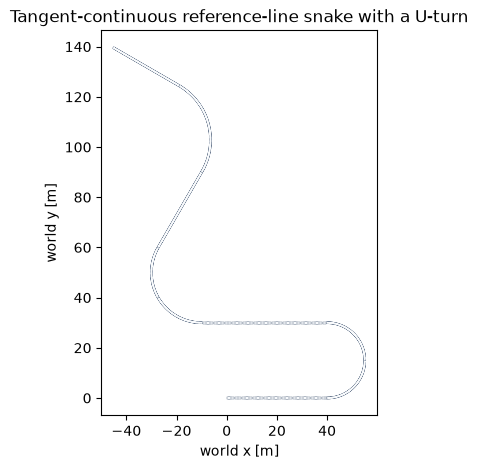

PosixPath('notebook_outputs/road-construction/reference-line-snake.png')

In [10]:
reference_line_figure, reference_line_axis = plt.subplots(figsize=(8.0, 5.0))
reference_line_plot_handles = reference_line_road.plot_road_on_matplotlib_axis(
    reference_line_axis,
    should_render_lanes=False,
    should_render_lane_lines=False,
    should_render_edge_bands=False,
    should_render_cones=False,
    should_render_reference_line=True,
)
reference_line_axis.set_title("Tangent-continuous reference-line snake with a U-turn")
reference_line_axis.set_xlabel("world x [m]")
reference_line_axis.set_ylabel("world y [m]")
reference_line_axis.set_aspect("equal", adjustable="box")
try:
    display(reference_line_figure)
    reference_line_plot_path = save_figure(
        reference_line_figure, OUTPUT_ROOT / "reference-line-snake.png"
    )
finally:
    plt.close(reference_line_figure)
reference_line_plot_path


### What you should see

The previous cell should have produced a plot showing an open, tangent-continuous reference-line containing straights, left and right arcs, and one geometric U-turn. No lane or shoulder surfaces are drawn yet.

## 2. Add a lane and shoulders around the reference line

The same element types, lengths, signed curvature/radius, sweeps, and speeds are reused from above. Only the first element declares the reference-line role, 3.6 m lane width, and shoulder widths; later elements inherit that cross-section.

### Conventions and definitions

The exact properties used by the next configuration cell are listed below. See the [course Road reference: geometry](../docs/road.md#geometry), [course Road reference: lanes and cross sections](../docs/road.md#lanes-and-cross-sections), and [course Road reference: edge bands](../docs/road.md#edge-bands).

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `elements[].geometry.type` | unitless | `straight` or `circular_arc` | Required on every element; never inherited | Reuses the fixed reference-line primitives |
| `elements[].geometry.length_m` | m | Finite and greater than zero | Required for every straight; never inherited | Reuses each straight length without changing the shape |
| `elements[].geometry.curvature_per_m` | m^-1 | Finite, nonzero, and magnitude at least `1e-4` under the constructor default | Required for every circular arc; never inherited | Reuses every signed turn and radius |
| `elements[].geometry.sweep_angle_deg` | degrees | Finite and greater than zero; exactly one of arc length or sweep is allowed | Required for the arcs used here; never inherited | Reuses every turn magnitude, including the U-turn |
| `elements[].speed_limit_kph` | km/h | Finite and greater than zero | First omission defaults to 100 km/h; later omission inherits the previous element | Preserves the fixed Road's explicit speed metadata |
| `elements[].lanes.reference_line_role` | unitless | `lane_center` or `lane_boundary` | First omission defaults to `lane_boundary`; later omission inherits | `lane_center` makes one physical lane around the target reference line |
| `elements[].lanes.reference_lane.width_m.start` | m | Finite and greater than zero | Required for a newly introduced centered lane; continuing omission inherits the prior end | Sets the full centered-lane width at element start |
| `elements[].lanes.reference_lane.width_m.end` | m | Finite and greater than zero | Omitted end defaults to start; continuing omitted widths inherit the prior end | Matches start so constant interpolation is valid |
| `elements[].edge_bands.<side>[].width_m.start` | m | Finite and nonnegative | Required for a newly introduced band; later omission inherits the prior end | Sets each shoulder width from the lane outward |
| `elements[].edge_bands.<side>[].width_m.end` | m | Finite and nonnegative | Omitted end defaults to start; continuing omitted widths inherit the prior end | Matches start so each shoulder stays constant width |


### The code for lanes and shoulders

The following cell give the code for adding lanes and shoulders, which hence specifies what we call the roads "cross-section". The reference line remains as the target line, i.e., as the line that we want our car to follow.

In [ ]:
# Specify the lane width and shoulders
# this one is the width between 2 sides
CENTERED_LANE_WIDTH_M = 3.6

#extra width from tarmac
TARMAC_SHOULDER = {
    "name": "tarmac_shoulder",
    "width_m": {"start": 0.6, "end": 0.6},
    "surface": "tarmac",
}
# extra dirt width
DIRT_SHOULDER = {
    "name": "dirt_shoulder",
    "width_m": {"start": 1.2, "end": 1.2},
    "surface": "dirt",
}

# Take a copy of the elements from the previous cells
CENTERED_ROAD_ELEMENTS = REFERENCE_LINE_ELEMENT_SPECS

# Add in  the lane width and shoulder specs
CENTERED_ROAD_ELEMENTS[0].update({
    "cross_section_width_interpolation": "constant",
    "lanes": {
        "reference_line_role": "lane_center",
        "reference_lane": {
            "width_m": {"start": CENTERED_LANE_WIDTH_M, "end": CENTERED_LANE_WIDTH_M},
            "surface": "tarmac",
        },
    },
    "edge_bands": {
        "left": [TARMAC_SHOULDER, DIRT_SHOULDER],
        "right": [TARMAC_SHOULDER, DIRT_SHOULDER],
    },
})
CENTERED_ROAD_SPEC = {"elements": CENTERED_ROAD_ELEMENTS}

# Construct the road
centered_road = Road(road_spec=CENTERED_ROAD_SPEC)


### Plot the reference line

The following cell plots the reference line **with lane and shoulders** that was specified in the previous cell.

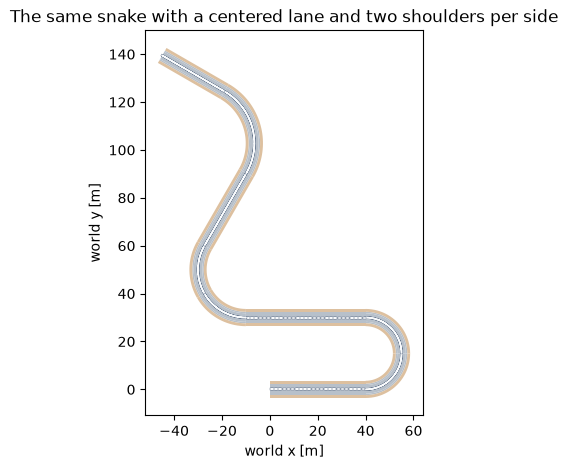

PosixPath('notebook_outputs/road-construction/ad_road_centered-snake.png')

In [12]:
centered_road_figure, centered_road_axis = plt.subplots(figsize=(8.0, 5.0))
centered_road_plot_handles = centered_road.plot_road_on_matplotlib_axis(centered_road_axis)
centered_road_axis.set_title("The same snake with a centered lane and two shoulders per side")
centered_road_axis.set_xlabel("world x [m]")
centered_road_axis.set_ylabel("world y [m]")
centered_road_axis.set_aspect("equal", adjustable="box")
try:
    display(centered_road_figure)
    centered_road_plot_path = save_road_plot(
        centered_road_figure,
        OUTPUT_ROOT,
        file_name_suffix="centered-snake",
        file_format="png",
    )
finally:
    plt.close(centered_road_figure)
centered_road_plot_path


### What you should see

The previous cell should have produced a plot showing the same reference-line this time surrounded by a centred lane with symmetric inner and outer shoulder bands on each side.

### Inspect the details of a constructed road

The following cell inspects and displays some of the details of the road that was constructed.

In [ ]:
road_element_metadata = centered_road.get_road_element_lane_metadata()
inspection_progresses_m = (
    0.0,
    0.5 * centered_road.total_length_m,
    max(0.0, centered_road.total_length_m - 1.0e-6),
)
centered_road_inspection = []
for progress_m in inspection_progresses_m:
    context = centered_road.get_road_progress_context(progress_m)
    centered_road_inspection.append({
        "progress_m": progress_m,
        "context": context,
        "metadata": road_element_metadata[context["element_index"]],
        "reference_lane_bounds": centered_road.get_reference_lane_bounds_at_progress(progress_m),
        "cross_section": centered_road.get_cross_section_at_progress(progress_m),
    })
for result in centered_road_inspection:
    print(
        f"progress={result['progress_m']:.2f} m, "
        f"element={result['context']['element_index']}, "
        f"lane bounds=({result['reference_lane_bounds']['right_bound_m']:.2f}, "
        f"{result['reference_lane_bounds']['left_bound_m']:.2f}) m"
    )


### What you should see

The previous cell should have displayed a few progress samples with stable, centred lane bounds while the element index changes. This shows that the inherited metadata keeps the cross-section consistent along the Road.

## 3. Hand-crafted Road

The editable parameters below form a simple starting point. Your task is to hand-craft this into a fun shape, such as the first letter of your name.

### Conventions and definitions

The exact properties used by the next configuration cell are listed below. See the [course Road reference: geometry](../docs/road.md#geometry), [course Road reference: lanes and cross sections](../docs/road.md#lanes-and-cross-sections), and [course Road reference: edge bands](../docs/road.md#edge-bands).

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `elements` | unitless | Nonempty ordered list for a populated Road | Required for a populated Road; no schema default | Orders four straight/arc pairs to close the shape |
| `elements[].geometry.type` | unitless | `straight` or `circular_arc` | Required on every element; never inherited | Alternates straight sides with rounded corners |
| `elements[].geometry.length_m` | m | Finite and greater than zero | Required for every straight; never inherited | Uses paired 80 m and 40 m opposite sides |
| `elements[].geometry.curvature_per_m` | m^-1 | Finite, nonzero, and magnitude at least `1e-4` under the constructor default | Required for every circular arc; never inherited | Four equal positive curvatures create equal-radius left corners |
| `elements[].geometry.sweep_angle_deg` | degrees | Finite and greater than zero; exactly one of arc length or sweep is allowed | Required for the arcs used here; never inherited | Four 90-degree sweeps make one complete turn |
| `elements[].speed_limit_kph` | km/h | Finite and greater than zero | First omission defaults to 100 km/h; later omission inherits the previous element | Explicitly sets every element to 50 km/h |
| `elements[].cross_section_width_interpolation` | unitless | `constant`, `linear`, or `smoothstep` | First omission defaults to `smoothstep`; later omission inherits | `constant` keeps the Road's lane and shoulders uniform |
| `elements[].lanes.reference_line_role` | unitless | `lane_center` or `lane_boundary` | First omission defaults to `lane_boundary`; later omission inherits | `lane_center` keeps the physical lane centered on the target |
| `elements[].lanes.reference_lane.width_m.start` | m | Finite and greater than zero | Required for a newly introduced centered lane; continuing omission inherits the prior end | Starts the Road with the same 3.6 m lane |
| `elements[].lanes.reference_lane.width_m.end` | m | Finite and greater than zero | Omitted end defaults to start; continuing omitted widths inherit the prior end | Matches start for a constant full lane width |
| `elements[].lanes.reference_lane.surface` | unitless | `tarmac`, `concrete`, `dirt`, or `grass` | First omission defaults to `tarmac`; later omission inherits | Keeps the centered lane tarmac |
| `elements[].edge_bands.<side>[].name` | unitless | Nonempty descriptive string | Optional; later omission inherits an earlier name, otherwise presentation defaults to `edge_band` | Names the two visible shoulder bands on each side |
| `elements[].edge_bands.<side>[].width_m.start` | m | Finite and nonnegative | Required for a newly introduced band; later omission inherits the prior end | Starts each shoulder at its fixed width |
| `elements[].edge_bands.<side>[].width_m.end` | m | Finite and nonnegative | Omitted end defaults to start; continuing omitted widths inherit the prior end | Matches start so the bands remain constant width |
| `elements[].edge_bands.<side>[].surface` | unitless | `tarmac`, `concrete`, `dirt`, or `grass` | First omission defaults to `grass`; later omission inherits | Retains inner tarmac and outer dirt shoulder surfaces |

The first element declares the 3.6 m centred tarmac lane and 0.6 m tarmac plus 1.2 m dirt shoulder widths; later elements inherit them. `Road(road_spec=...)` validates the specification and keeps the reference line as the target line. Edit only the geometry and speed-limit parameters in the next cell.


### Road elements spec and plot

The following cell:
* Specifies the elements of the hand-crafted road;
* Adds the lane specs to it; and
* Plots the road.

We put this all in one code cell so that it is quicker to iterate on your hand-crafted road.

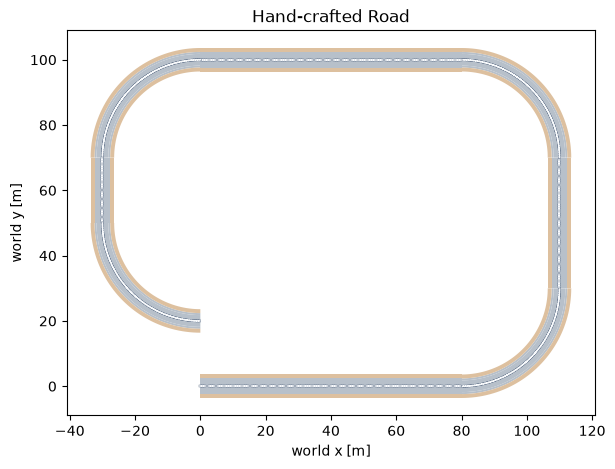

PosixPath('notebook_outputs/road-construction/ad_road_hand_crafted-road.png')

In [13]:
# Specify the road elements
HAND_CRAFTED_ROAD_ELEMENTS = [
    {"speed_limit_kph": 80.0, "geometry":{"type": "straight", "length_m": 80.0}},
    {"geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 30.0, "sweep_angle_deg": 90.0}},
    {"geometry":{"type": "straight", "length_m": 40.0}},
    {"geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 30.0, "sweep_angle_deg": 90.0}},
    {"geometry":{"type": "straight", "length_m": 80.0}},
    {"geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 30.0, "sweep_angle_deg": 90.0}},
    {"geometry":{"type": "straight", "length_m": 20.0}},
    {"geometry":{"type": "circular_arc", "curvature_per_m": 1.0 / 30.0, "sweep_angle_deg": 90.0}},
]

# Add the lane specs
HAND_CRAFTED_ROAD_ELEMENTS[0].update({
    "cross_section_width_interpolation": "constant",
    "lanes": {
        "reference_line_role": "lane_center",
        "reference_lane": {
            "width_m": {"start": CENTERED_LANE_WIDTH_M, "end": CENTERED_LANE_WIDTH_M},
            "surface": "tarmac",
        },
    },
    "edge_bands": {
        "left": [TARMAC_SHOULDER, DIRT_SHOULDER],
        "right": [TARMAC_SHOULDER, DIRT_SHOULDER],
    },
})

# Construct the road
HAND_CRAFTED_ROAD_SPEC = {"elements": list(HAND_CRAFTED_ROAD_ELEMENTS)}
hand_crafted_road = Road(road_spec=HAND_CRAFTED_ROAD_SPEC)

# Plot the road
hand_crafted_road_figure, hand_crafted_road_axis = plt.subplots(figsize=(7.0, 5.0))
hand_crafted_road_plot_handles = hand_crafted_road.plot_road_on_matplotlib_axis(hand_crafted_road_axis)
hand_crafted_road_axis.set_title("Hand-crafted Road")
hand_crafted_road_axis.set_xlabel("world x [m]")
hand_crafted_road_axis.set_ylabel("world y [m]")
hand_crafted_road_axis.set_aspect("equal", adjustable="box")
try:
    display(hand_crafted_road_figure)
    hand_crafted_road_plot_path = save_road_plot(
        hand_crafted_road_figure,
        OUTPUT_ROOT,
        file_name_suffix="hand_crafted-road",
        file_format="png",
    )
finally:
    plt.close(hand_crafted_road_figure)
hand_crafted_road_plot_path


### What you should see

The previous cell should show a plot of the hand-crafted road.

### Your turn

Edit `HAND_CRAFTED_ROAD_ELEMENTS` above to hand-craft a road in a "fun" shape, for example, to look like the first letter or your name.

### Animate the road

Watching an animation of a non-simulated car moving along your road can be a fun visualization, though not usually necessary. This feature is mainly included for a bit of extra "fun".

Run the following cell to proudce the animation, and then navigate to the folder where it was saved.

In `smoke` mode, a short deterministic marker preview along the hand-crafted Road. In `full` mode, the marker completes the full reference-line traversal.

**Note**: the vehicle is **NOT** being simulated! The vehicle is simply being progressed along the road at a fixed speed.

In [14]:
hand_crafted_road_animation_path = OUTPUT_ROOT / "hand-crafted-road.gif"
animation_details = hand_crafted_road.animate_reference_line_drive_with_matplotlib(
    speed_mode=MODE["animation_speed_mode"],
    speed_mps=MODE["animation_speed_mps"],
    fps=MODE["animation_fps"],
    max_duration_s=MODE["animation_max_duration_s"],
    dpi=MODE["animation_dpi"],
    figure_size=MODE["animation_figure_size"],
    intro_duration_s=MODE["animation_intro_duration_s"],
    should_render_speed_signs=True,
    speed_sign_display_mode="roadside", # Options: "roadside", "fixed", "both"
    save_path=hand_crafted_road_animation_path,
    writer="pillow",
    return_animation=False,
    return_details=True,
)
try:
    print(f"Saved non-simulated Road presentation: {hand_crafted_road_animation_path}")
finally:
    plt.close(animation_details["figure"])


Saved non-simulated Road presentation: notebook_outputs/road-construction/hand-crafted-road.gif


## 4. Random Road Generation

The Gymnasium includes functions and parameters for automatically generating roads with randomized shapes. Random road are very useful for RL training and for performing automated evaluation of any policy. The challenge of random roads is to ensure the all the roads generated are sensible.

### Conventions and definitions

There are two important function for random roads:

* `normalize_random_road_generation_config(...)` checks the validity of the parameters provided for random road generate and fills any omitted parameters with default values.
* `generate_random_road_spec(generation_config=..., seed=...)` then uses a nonnegative integer seed to create a deterministic Road specification: the same configuration and seed produce the same specification.

**Note:** `Road(road_spec=...)`, which we already used above for constructing road remains the strict public validation boundary for each generated specification.

The exact properties in the configuration cell are documented here. See the [course Road reference: random generation](../docs/road.md#random-road-generation).

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `element_count_range.lower` | unitless | Integer at least 1 | Default available if omitted | Sets the sampled element count's lower endpoint |
| `element_count_range.upper` | unitless | Integer no smaller than lower | Default available if omitted | Sets the sampled element count's upper endpoint |
| `straight_element_probability` | unitless | Finite value in [0, 1] | Default available if omitted | Balances later straight and arc elements |
| `straight.length_range_m.lower` | m | Positive finite value | Default available if omitted | Bounds sampled non-first straight lengths below |
| `straight.length_range_m.upper` | m | Positive finite value no smaller than lower | Default available if omitted | Bounds sampled non-first straight lengths above |
| `circular_arc.radius_range_m.lower` | m | Positive finite value | Default available if omitted | Bounds sampled circular-arc radii below |
| `circular_arc.radius_range_m.upper` | m | Positive finite value no smaller than lower | Default available if omitted | Bounds sampled circular-arc radii above |
| `circular_arc.sweep_angle_range_deg.lower` | degrees | Positive finite value | Default available if omitted | Bounds sampled arc sweep angles below |
| `circular_arc.sweep_angle_range_deg.upper` | degrees | Positive finite value no smaller than lower | Default available if omitted | Bounds sampled arc sweep angles above |
| `speed_limit_range_kph.lower` | km/h | Positive finite value | Default available if omitted | Bounds per-element speed limits below |
| `speed_limit_range_kph.upper` | km/h | Positive finite value no smaller than lower | Default available if omitted | Bounds per-element speed limits above |
| `first_element.require_straight` | unitless | Boolean | Default available if omitted | Makes every generated Road begin predictably |
| `first_element.straight_length_range_m.lower` | m | Positive finite value | Default available if omitted | Bounds the required first straight below |
| `first_element.straight_length_range_m.upper` | m | Positive finite value no smaller than lower | Default available if omitted | Bounds the required first straight above |
| `initial_cross_section.reference_line_role` | unitless | `lane_center` or `lane_boundary` | Default available if omitted | Chooses the centered reference-lane form |
| `initial_cross_section.reference_lane_width_range_m.lower` | m | Positive finite value with `lane_center` | Default available if omitted | Fixes the centered lane width's lower endpoint |
| `initial_cross_section.reference_lane_width_range_m.upper` | m | Positive finite value no smaller than lower | Default available if omitted | Fixes the centered lane width's upper endpoint |
| `active_lane_minimum_width_m` | m | Finite value at least 0 | Default available if omitted | Retains the public active-lane threshold |

The next cell is a guided parameter activity. Students may change **only ranges and probabilities** there. The nine-seed generation, public validation, plotting, labels, layout, and saving plumbing remain complete and non-editable.

### The code for the random road config

The configuration below, which you will edit when it is "your turn" deliberately creates tight curvey roads. The required first straight keeps every Road's opening predictable.

Additionally, the configuration below keeps the reference line as the target and fixes a centred 3.6 m lane.

The second code cell below is a helper for drawing 9 samples of a random road and then plotting them all in one figure.


In [17]:
RANDOM_ROAD_CONFIG = {
    "element_count_range": {
        "lower": 8,
        "upper": 12
    },
    "straight_element_probability": 0.40,
    "straight": {
        "length_range_m": {
            "lower": 20.0,
            "upper": 60.0
        }
    },
    "circular_arc": {
        "radius_range_m": {
            "lower": 20.0,
            "upper": 60.0
        },
        "sweep_angle_range_deg": {
            "lower": 30.0,
            "upper": 120.0
        }
    },
    "speed_limit_range_kph": {
        "lower": 40.0,
        "upper": 80.0
    },
    "first_element": {
        "require_straight": True,
        "straight_length_range_m": {
            "lower": 30.0,
            "upper": 50.0
        }
    },
    "initial_cross_section": {
        "reference_line_role": "lane_center",
        "reference_lane_width_range_m": {
            "lower": 3.6,
            "upper": 3.6
        }
    },
    "active_lane_minimum_width_m": 0.05,
}

random_road_generation_config = (
    normalize_random_road_generation_config(
        RANDOM_ROAD_CONFIG
    )
)

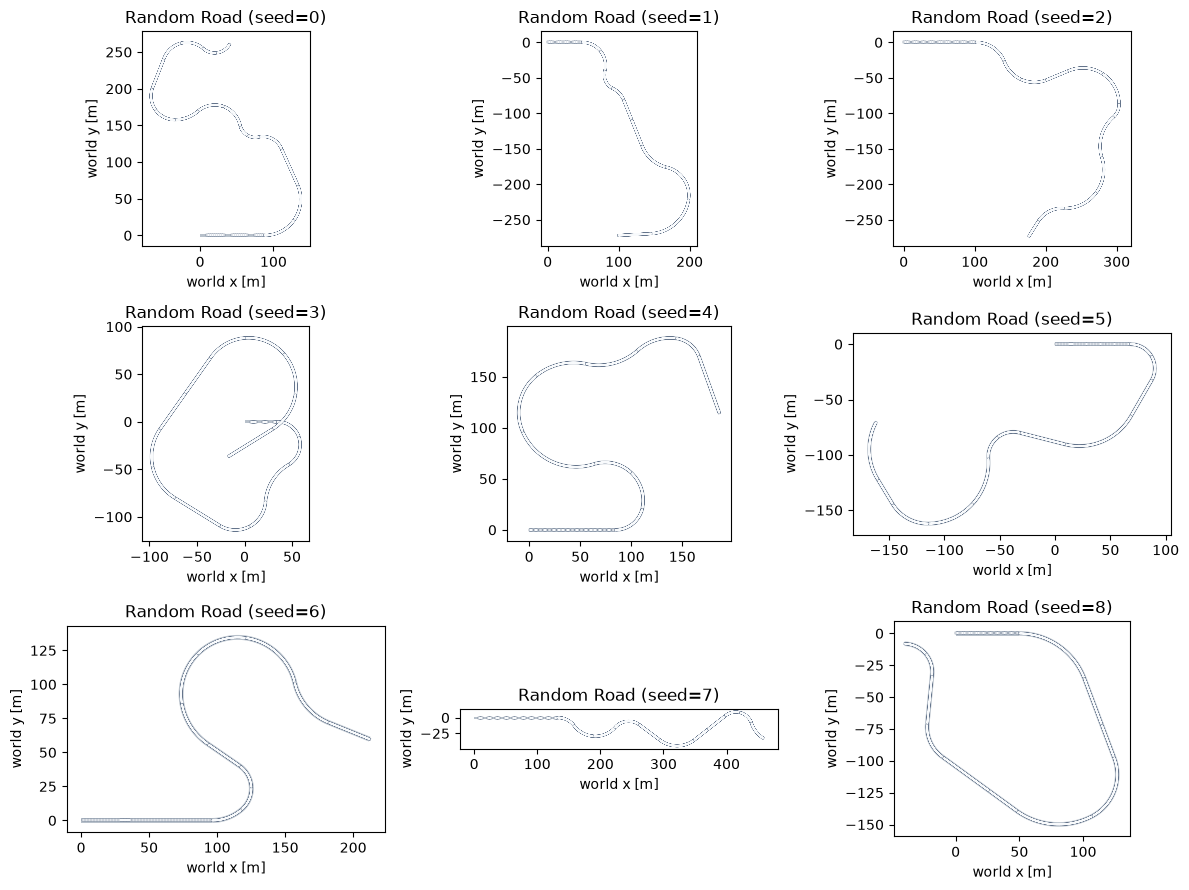

PosixPath('notebook_outputs/road-construction/random-road-grid.png')

In [18]:
def plot_random_road_grid(generation_config, seeds, output_path) -> RandomRoadGridResult:
    if len(seeds) != 9 or len(set(seeds)) != 9:
        raise ValueError("seeds must contain exactly nine distinct values")

    figure, axes = plt.subplots(3, 3, figsize=(12.0, 9.0))
    roads = []
    for axis, seed in zip(axes.flat, seeds):
        road_spec = generate_random_road_spec(
            generation_config=generation_config, seed=seed
        )
        road = Road(road_spec=road_spec)
        road.plot_road_on_matplotlib_axis(axis)
        axis.set_title(f"Random Road (seed={seed})")
        axis.set_xlabel("world x [m]")
        axis.set_ylabel("world y [m]")
        axis.set_aspect("equal", adjustable="box")
        roads.append(road)

    figure.tight_layout()
    try:
        display(figure)
        save_path = save_figure(figure, output_path)
    finally:
        plt.close(figure)
    return {"figure": figure, "roads": tuple(roads), "save_path": save_path}

RANDOM_ROAD_GRID_SEEDS = (0, 1, 2, 3, 4, 5, 6, 7, 8)
random_road_grid = plot_random_road_grid(
    random_road_generation_config,
    RANDOM_ROAD_GRID_SEEDS,
    OUTPUT_ROOT / "random-road-grid.png",
)
random_road_grid["save_path"]


### What you should see

The previous cell should show a figure with a 3x3 grid of nine road drawn from the random road configuration.

### Your turn

Edit `RANDOM_ROAD_CONFIG` above to get a balance of **straights** and **turns**. Aim for useful diversity rather than a stress test, then rerun the plot.